In [128]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [129]:
# objective:
# predict whteehr an activity is Normal or Attack
# Predict whetehr the activity is Normal or Back or Buffer Over flow or FTP Write or Guess Password or Neptune or N-Map or Port Sweep or Root Kit or Satan or Smurf

In [130]:
"""
pipeline followed

Load the data
EDA
Preprocessing: cleaning, feature engineering
train test split
missing value imputation
feature encoding
feature selection
model building
train and validate
test
"""

'\npipeline followed\n\nLoad the data\nEDA\nPreprocessing: cleaning, feature engineering\ntrain test split\nmissing value imputation\nfeature encoding\nfeature selection\nmodel building\ntrain and validate\ntest\n'

In [132]:
!pip install imbalanced-learn

In [133]:
!pip install xgboost

In [134]:
# all the necessary headers for this project

In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.impute import KNNImputer, SimpleImputer

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_selection import RFE
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [136]:
filepath = '/content/drive/My Drive/Analytix labs case studies/Cyber Security/'
df1 = pd.read_csv(filepath + 'Data_of_Attack_Back_BufferOverflow.csv')
df2 = pd.read_csv(filepath + 'Data_of_Attack_Back_FTPWrite.csv')
df3 = pd.read_csv(filepath + 'Data_of_Attack_Back_GuessPassword.csv')
df4 = pd.read_csv(filepath + 'Data_of_Attack_Back_Neptune.csv')
df5 = pd.read_csv(filepath + 'Data_of_Attack_Back_NMap.csv')
df6 = pd.read_csv(filepath + 'Data_of_Attack_Back_Normal.csv')
df7 = pd.read_csv(filepath + 'Data_of_Attack_Back_PortSweep.csv')
df8 = pd.read_csv(filepath + 'Data_of_Attack_Back_RootKit.csv')
df9 = pd.read_csv(filepath + 'Data_of_Attack_Back_Satan.csv')
df10 = pd.read_csv(filepath + 'Data_of_Attack_Back_Smurf.csv')
df11 = pd.read_csv(filepath + 'Data_of_Attack_Back.csv')

In [137]:
# check the data heads

In [138]:
df1.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0184,0,0.05,0.0,0.01511,0.02957,0,0,0,0.3,...,0.001,0.003,0.1,0,0.10,0.067,0,0,0.0,0.0
1,0.0305,0,0.05,0.0,0.01735,0.02766,0,0,0,0.3,...,0.002,0.004,0.1,0,0.05,0.050,0,0,0.0,0.0
2,0.0150,0,0.05,0.0,0.01587,0.06707,0,0,0,0.1,...,0.001,0.001,0.1,0,0.10,0.000,0,0,0.0,0.0
3,0.0060,0,0.05,0.0,0.02328,0.04551,0,0,0,0.3,...,0.001,0.001,0.1,0,0.10,0.000,0,0,0.0,0.0
4,0.0158,0,0.05,0.0,0.01567,0.03095,0,0,0,0.3,...,0.002,0.002,0.1,0,0.05,0.000,0,0,0.0,0.0


In [139]:
df2.head()

,0.0026,0,0.07,0.3,0.00116,0.00451,0.4,0.5,0.6,0.2,...,0.001.2,0.001.3,0.1.5,0.21,0.1.6,0.22,0.23,0.24,0.25,0.26
0,0.0134,0,0.34,0,0.00100,0.39445,0,0,0.2,0.0,...,0.002,0.001,0.05,0.1,0.05,0.000,0,0,0,0
1,0.0000,0,0.14,0,0.00613,0.00000,0,0,0.0,0.0,...,0.001,0.084,0.10,0.0,0.10,0.002,0,0,0,0
2,0.0000,0,0.14,0,0.00000,0.00005,0,0,0.0,0.0,...,0.002,0.085,0.10,0.0,0.10,0.002,0,0,0,0
3,0.0032,0,0.07,0,0.00104,0.00449,0,0,0.0,0.2,...,0.001,0.001,0.10,0.0,0.10,0.000,0,0,0,0
4,0.0067,0,0.34,0,0.00157,0.02703,0,0,0.1,0.0,...,0.002,0.001,0.05,0.1,0.05,0.000,0,0,0,0


In [140]:
df3.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0023,0,0.05,0.00,0.00104,0.00276,0,0,0,0.0,...,0.001,0.002,0.1,0,0.100,0.1,0.000,0.000,0.000,0.000
1,0.0060,0,0.05,0.03,0.00125,0.00179,0,0,0,0.1,...,0.001,0.001,0.1,0,0.100,0.0,0.100,0.100,0.000,0.000
2,0.0000,0,0.05,0.06,0.00125,0.00179,0,0,0,0.1,...,0.002,0.002,0.1,0,0.050,0.0,0.050,0.050,0.050,0.050
3,0.0000,0,0.05,0.06,0.00125,0.00179,0,0,0,0.1,...,0.003,0.003,0.1,0,0.033,0.0,0.033,0.033,0.067,0.067
4,0.0000,0,0.05,0.06,0.00125,0.00179,0,0,0,0.1,...,0.004,0.004,0.1,0,0.025,0.0,0.025,0.025,0.075,0.075


In [141]:
df4.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0,0,0.05,0.07,0.0,0.0,0,0,0,0,...,0.001,0.002,0.1,0.0,0.100,0.100,0.1,0.050,0.0,0.0
1,0.0,0,0.05,0.07,0.0,0.0,0,0,0,0,...,0.002,0.003,0.1,0.0,0.050,0.067,0.1,0.067,0.0,0.0
2,0.0,0,0.05,0.07,0.0,0.0,0,0,0,0,...,0.003,0.004,0.1,0.0,0.033,0.050,0.1,0.075,0.0,0.0
3,0.0,0,0.05,0.07,0.0,0.0,0,0,0,0,...,0.004,0.005,0.1,0.0,0.025,0.040,0.1,0.080,0.0,0.0
4,0.0,0,0.05,0.07,0.0,0.0,0,0,0,0,...,0.005,0.006,0.1,0.0,0.020,0.033,0.1,0.083,0.0,0.0


In [142]:
df5.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,0.02,0.06,0.0,0.00008,0.0,0,0,0,0,...,0.003,0.001,0.033,0.100,0.033,0.0,0.0,0.0,0,0
1,0,0.02,0.06,0.0,0.00008,0.0,0,0,0,0,...,0.004,0.002,0.050,0.075,0.050,0.0,0.0,0.0,0,0
2,0,0.02,0.06,0.0,0.00008,0.0,0,0,0,0,...,0.005,0.003,0.060,0.060,0.060,0.0,0.0,0.0,0,0
3,0,0.02,0.06,0.0,0.00008,0.0,0,0,0,0,...,0.006,0.004,0.067,0.050,0.067,0.0,0.0,0.0,0,0
4,0,0.02,0.06,0.0,0.00008,0.0,0,0,0,0,...,0.007,0.005,0.071,0.043,0.071,0.0,0.0,0.0,0,0


In [143]:
df6.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0,0.0,0.0,0.0,0.00215,0.45076,0,0,0.0,0.0,...,0.000,0.000,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.00162,0.04528,0,0,0.0,0.0,...,0.001,0.001,0.1,0.0,0.100,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.00236,0.01228,0,0,0.0,0.0,...,0.002,0.002,0.1,0.0,0.050,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.00233,0.02032,0,0,0.0,0.0,...,0.003,0.003,0.1,0.0,0.033,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.00239,0.00486,0,0,0.0,0.0,...,0.004,0.004,0.1,0.0,0.025,0.0,0.0,0.0,0.0,0.0


In [144]:
df7.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0000,0.0,0.14,0.05,0.0,0.0,0,0,0,0.0,...,0.171,0.062,0.027,0.002,0.001,0.003,0.001,0.0,0.029,0.002
1,0.0001,0.0,0.14,0.08,0.0,0.0,0,0,0,0.0,...,0.172,0.062,0.027,0.002,0.001,0.003,0.001,0.0,0.030,0.003
2,0.0000,0.0,0.12,0.05,0.0,0.0,0,0,0,0.0,...,0.173,0.001,0.001,0.003,0.002,0.000,0.001,0.0,0.030,0.100
3,0.0001,0.0,0.12,0.08,0.0,0.0,0,0,0,0.0,...,0.174,0.002,0.001,0.003,0.002,0.000,0.001,0.0,0.030,0.100
4,0.0000,0.0,0.12,0.05,0.0,0.0,0,0,0,0.0,...,0.175,0.001,0.001,0.003,0.003,0.000,0.001,0.0,0.031,0.100


In [145]:
df8.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0060,0.0,0.05,0,0.00086,0.00183,0,0,0.0,0.0,...,0.255,0.001,0.000,0.002,0.0,0.0,0,0.0,0.0,0.0
1,0.0060,0.0,0.05,0,0.00090,0.00233,0,0,0.0,0.0,...,0.255,0.002,0.001,0.002,0.0,0.0,0,0.0,0.0,0.0
2,0.0708,0.0,0.05,0,0.01727,0.24080,0,0,0.0,0.0,...,0.255,0.003,0.001,0.002,0.0,0.0,0,0.0,0.0,0.0
3,0.0021,0.0,0.07,0,0.00089,0.00345,0,0,0.0,0.1,...,0.255,0.001,0.000,0.002,0.0,0.0,0,0.0,0.0,0.0
4,0.0098,0.0,0.05,0,0.00621,0.08356,0,0,0.1,0.1,...,0.255,0.004,0.002,0.002,0.0,0.0,0,0.0,0.0,0.0


In [146]:
df9.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0,0.02,0.06,0.0,0.00020,0.0,0,0,0,0.0,...,0.143,0.001,0.001,0.004,0.001,0.0,0.001,0.0,0.0,0.0
1,0.0,0.02,0.06,0.0,0.00020,0.0,0,0,0,0.0,...,0.144,0.002,0.001,0.004,0.002,0.0,0.001,0.0,0.0,0.0
2,0.0,0.02,0.06,0.0,0.00020,0.0,0,0,0,0.0,...,0.145,0.003,0.002,0.004,0.003,0.0,0.001,0.0,0.0,0.0
3,0.0,0.01,0.12,0.0,0.00001,0.0,0,0,0,0.0,...,0.146,0.001,0.001,0.005,0.001,0.0,0.001,0.0,0.0,0.0
4,0.0,0.01,0.12,0.0,0.00001,0.0,0,0,0,0.0,...,0.147,0.002,0.001,0.005,0.001,0.0,0.001,0.0,0.0,0.0


In [147]:
df10.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,0.02,0.09,0,0.01032,0,0,0.0,0,0,...,0.146,0.001,0.001,0.002,0.001,0,0.0,0,0.0,0
1,0,0.02,0.09,0,0.01032,0,0,0.0,0,0,...,0.147,0.002,0.001,0.002,0.001,0,0.0,0,0.0,0
2,0,0.02,0.09,0,0.01032,0,0,0.0,0,0,...,0.148,0.003,0.002,0.002,0.002,0,0.0,0,0.0,0
3,0,0.02,0.09,0,0.01032,0,0,0.0,0,0,...,0.149,0.004,0.003,0.002,0.003,0,0.0,0,0.0,0
4,0,0.02,0.09,0,0.01032,0,0,0.0,0,0,...,0.150,0.005,0.003,0.002,0.003,0,0.0,0,0.0,0


In [148]:
df11.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0,0,0,0.0,0.5454,0.08314,0,0,0,0.2,...,0.001,0.001,0.1,0,0.100,0,0.0,0.0,0.0,0.0
1,0.0,0,0,0.0,0.5454,0.08314,0,0,0,0.2,...,0.002,0.002,0.1,0,0.050,0,0.0,0.0,0.0,0.0
2,0.0,0,0,0.0,0.5454,0.08314,0,0,0,0.2,...,0.003,0.003,0.1,0,0.033,0,0.0,0.0,0.0,0.0
3,0.0,0,0,0.0,0.5454,0.08314,0,0,0,0.2,...,0.004,0.004,0.1,0,0.025,0,0.0,0.0,0.0,0.0
4,0.0,0,0,0.0,0.5454,0.08314,0,0,0,0.2,...,0.005,0.005,0.1,0,0.020,0,0.0,0.0,0.0,0.0


In [149]:
# check the shape

In [150]:
df1.shape

(30, 41)

In [151]:
df2.shape

(7, 41)

In [152]:
df3.shape

(53, 41)

In [153]:
df4.shape

(227228, 41)

In [154]:
df5.shape

(1554, 41)

In [155]:
df6.shape

(576710, 41)

In [156]:
df7.shape

(2964, 41)

In [157]:
df8.shape

(10, 41)

In [158]:
df9.shape

(5019, 41)

In [159]:
df10.shape

(3007, 41)

In [160]:
df11.shape

(968, 41)

In [161]:
# check the columns in the datasets

In [162]:
df1.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [163]:
df2.columns.to_list()

['0.0026',
 ' 0',
 ' 0.07',
 ' 0.3',
 ' 0.00116',
 ' 0.00451',
 ' 0.4',
 ' 0.5',
 ' 0.6',
 ' 0.2',
 ' 0.7',
 ' 0.1',
 ' 0.8',
 ' 0.9',
 ' 0.10',
 ' 0.11',
 ' 0.1.1',
 ' 0.12',
 ' 0.1.2',
 ' 0.13',
 ' 0.14',
 ' 0.1.3',
 ' 0.001',
 ' 0.001.1',
 ' 0.15',
 ' 0.16',
 ' 0.17',
 ' 0.18',
 ' 0.1.4',
 ' 0.19',
 ' 0.20',
 ' 0.001.2',
 ' 0.001.3',
 ' 0.1.5',
 ' 0.21',
 ' 0.1.6',
 ' 0.22',
 ' 0.23',
 ' 0.24',
 ' 0.25',
 ' 0.26']

In [164]:
df3.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [165]:
df4.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [166]:
df5.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [167]:
df6.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [168]:
df7.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [169]:
df8.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [170]:
df9.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [171]:
df10.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [172]:
df11.columns.to_list()

['duration',
 ' protocol_type',
 ' service',
 ' flag',
 ' src_bytes',
 ' dst_bytes',
 ' land',
 ' wrong_fragment',
 ' urgent',
 ' hot',
 ' num_failed_logins',
 ' logged_in',
 ' num_compromised',
 ' root_shell',
 ' su_attempted',
 ' num_root',
 ' num_file_creations',
 ' num_shells',
 ' num_access_files',
 ' num_outbound_cmds',
 ' is_host_login',
 ' is_guest_login',
 ' count',
 ' srv_count',
 ' serror_rate',
 ' srv_error_rate',
 ' rerror_rate',
 ' srv_rerror_rate',
 ' same_srv_rate',
 ' diff_srv_rate',
 ' srv_diff_host_rate',
 ' dst_host_count',
 ' dst_host_srv_count',
 ' dst_host_same_srv_rate',
 ' dst_host_diff_srv_rate',
 ' dst_host_same_src_port_rate',
 ' dst_host_srv_diff_host_rate',
 ' dst_host_serror_rate',
 ' dst_host_srv_serror_rate',
 ' dst_host_rerror_rate',
 ' dst_host_srv_rerror_rate']

In [173]:
df1.columns == df3.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [174]:
# every other dataset have 41 columns with the same name

In [175]:
# let's reload df2 and assign the proper column names to df2

In [176]:
df2 = pd.read_csv(filepath + 'Data_of_Attack_Back_FTPWrite.csv', header = None)

In [177]:
df2.columns = df1.columns
df2.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0026,0,0.07,0,0.00116,0.00451,0,0,0.0,0.2,...,0.001,0.001,0.10,0.0,0.10,0.000,0,0,0,0
1,0.0134,0,0.34,0,0.00100,0.39445,0,0,0.2,0.0,...,0.002,0.001,0.05,0.1,0.05,0.000,0,0,0,0
2,0.0000,0,0.14,0,0.00613,0.00000,0,0,0.0,0.0,...,0.001,0.084,0.10,0.0,0.10,0.002,0,0,0,0
3,0.0000,0,0.14,0,0.00000,0.00005,0,0,0.0,0.0,...,0.002,0.085,0.10,0.0,0.10,0.002,0,0,0,0
4,0.0032,0,0.07,0,0.00104,0.00449,0,0,0.0,0.2,...,0.001,0.001,0.10,0.0,0.10,0.000,0,0,0,0


In [178]:
# now we will have to add 'attack' feature to each of these datasets
"""
df1 = pd.read_csv(filepath + 'Data_of_Attack_Back_BufferOverflow.csv')
df2 = pd.read_csv(filepath + 'Data_of_Attack_Back_FTPWrite.csv')
df3 = pd.read_csv(filepath + 'Data_of_Attack_Back_GuessPassword.csv')
df4 = pd.read_csv(filepath + 'Data_of_Attack_Back_Neptune.csv')
df5 = pd.read_csv(filepath + 'Data_of_Attack_Back_NMap.csv')
df6 = pd.read_csv(filepath + 'Data_of_Attack_Back_Normal.csv')
df7 = pd.read_csv(filepath + 'Data_of_Attack_Back_PortSweep.csv')
df8 = pd.read_csv(filepath + 'Data_of_Attack_Back_RootKit.csv')
df9 = pd.read_csv(filepath + 'Data_of_Attack_Back_Satan.csv')
df10 = pd.read_csv(filepath + 'Data_of_Attack_Back_Smurf.csv')
df11 = pd.read_csv(filepath + 'Data_of_Attack_Back.csv')
"""

"\ndf1 = pd.read_csv(filepath + 'Data_of_Attack_Back_BufferOverflow.csv')\ndf2 = pd.read_csv(filepath + 'Data_of_Attack_Back_FTPWrite.csv')\ndf3 = pd.read_csv(filepath + 'Data_of_Attack_Back_GuessPassword.csv')\ndf4 = pd.read_csv(filepath + 'Data_of_Attack_Back_Neptune.csv')\ndf5 = pd.read_csv(filepath + 'Data_of_Attack_Back_NMap.csv')\ndf6 = pd.read_csv(filepath + 'Data_of_Attack_Back_Normal.csv')\ndf7 = pd.read_csv(filepath + 'Data_of_Attack_Back_PortSweep.csv')\ndf8 = pd.read_csv(filepath + 'Data_of_Attack_Back_RootKit.csv')\ndf9 = pd.read_csv(filepath + 'Data_of_Attack_Back_Satan.csv')\ndf10 = pd.read_csv(filepath + 'Data_of_Attack_Back_Smurf.csv')\ndf11 = pd.read_csv(filepath + 'Data_of_Attack_Back.csv')\n"

In [179]:
df1['attack'] = 'Buffer Overflow'
df2['attack'] = 'FTP Write'
df3['attack'] = 'Guess Password'
df4['attack'] = 'Neptune'
df5['attack'] = 'N-Map'
df6['attack'] = 'Normal'
df7['attack'] = 'Port Sweep'
df8['attack'] = 'Root Kit'
df9['attack'] = 'Satan'
df10['attack'] = 'Smurf'
df11['attack'] = 'Back'

In [180]:
# combine all the datasets

In [181]:
df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10, df11], axis = 0, ignore_index = True)

In [182]:
# check the head and shape

In [183]:
df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack
0,0.0184,0.0,0.05,0.0,0.01511,0.02957,0,0.0,0.0,0.3,...,0.003,0.1,0.0,0.10,0.067,0.0,0.0,0.0,0.0,Buffer Overflow
1,0.0305,0.0,0.05,0.0,0.01735,0.02766,0,0.0,0.0,0.3,...,0.004,0.1,0.0,0.05,0.050,0.0,0.0,0.0,0.0,Buffer Overflow
2,0.0150,0.0,0.05,0.0,0.01587,0.06707,0,0.0,0.0,0.1,...,0.001,0.1,0.0,0.10,0.000,0.0,0.0,0.0,0.0,Buffer Overflow
3,0.0060,0.0,0.05,0.0,0.02328,0.04551,0,0.0,0.0,0.3,...,0.001,0.1,0.0,0.10,0.000,0.0,0.0,0.0,0.0,Buffer Overflow
4,0.0158,0.0,0.05,0.0,0.01567,0.03095,0,0.0,0.0,0.3,...,0.002,0.1,0.0,0.05,0.000,0.0,0.0,0.0,0.0,Buffer Overflow


In [184]:
df.shape

(817551, 42)

In [185]:
# check the value count for attack

In [186]:
df.attack.value_counts()

,count
attack,
Normal,576710
Neptune,227228
Satan,5019
Smurf,3007
Port Sweep,2964
N-Map,1554
Back,968
Guess Password,53
Buffer Overflow,30


In [187]:
# EDA

In [188]:
# missing value, duplicated records, data types

In [189]:
df.isna().sum()

,0
duration,0
protocol_type,0
service,0
flag,0
src_bytes,0
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0


In [190]:
# no missing values

In [191]:
df.duplicated().sum()

np.int64(0)

In [192]:
# no duplicate records

In [193]:
df.dtypes

,0
duration,float64
protocol_type,float64
service,float64
flag,float64
src_bytes,float64
dst_bytes,float64
land,int64
wrong_fragment,float64
urgent,float64
hot,float64


In [194]:
# correct the names of columns in df

In [195]:
df.columns = df.columns.str.replace(r'[^A-Za-z0-9_]', '', regex = True)

In [196]:
# separate cat and num features

In [197]:
cat_cols = [
    'protocol_type', 'service', 'flag',
    'land', 'logged_in', 'root_shell',
    'su_attempted', 'is_host_login', 'is_guest_login'
]

In [198]:
num_cols = [col for col in df.columns if col not in cat_cols + ['attack']]
num_cols

['duration',
 'src_bytes',
 'dst_bytes',
 'wrong_fragment',
 'urgent',
 'hot',
 'num_failed_logins',
 'num_compromised',
 'num_root',
 'num_file_creations',
 'num_shells',
 'num_access_files',
 'num_outbound_cmds',
 'count',
 'srv_count',
 'serror_rate',
 'srv_error_rate',
 'rerror_rate',
 'srv_rerror_rate',
 'same_srv_rate',
 'diff_srv_rate',
 'srv_diff_host_rate',
 'dst_host_count',
 'dst_host_srv_count',
 'dst_host_same_srv_rate',
 'dst_host_diff_srv_rate',
 'dst_host_same_src_port_rate',
 'dst_host_srv_diff_host_rate',
 'dst_host_serror_rate',
 'dst_host_srv_serror_rate',
 'dst_host_rerror_rate',
 'dst_host_srv_rerror_rate']

In [199]:
# univariate analysis --> visualize the num features and cat features

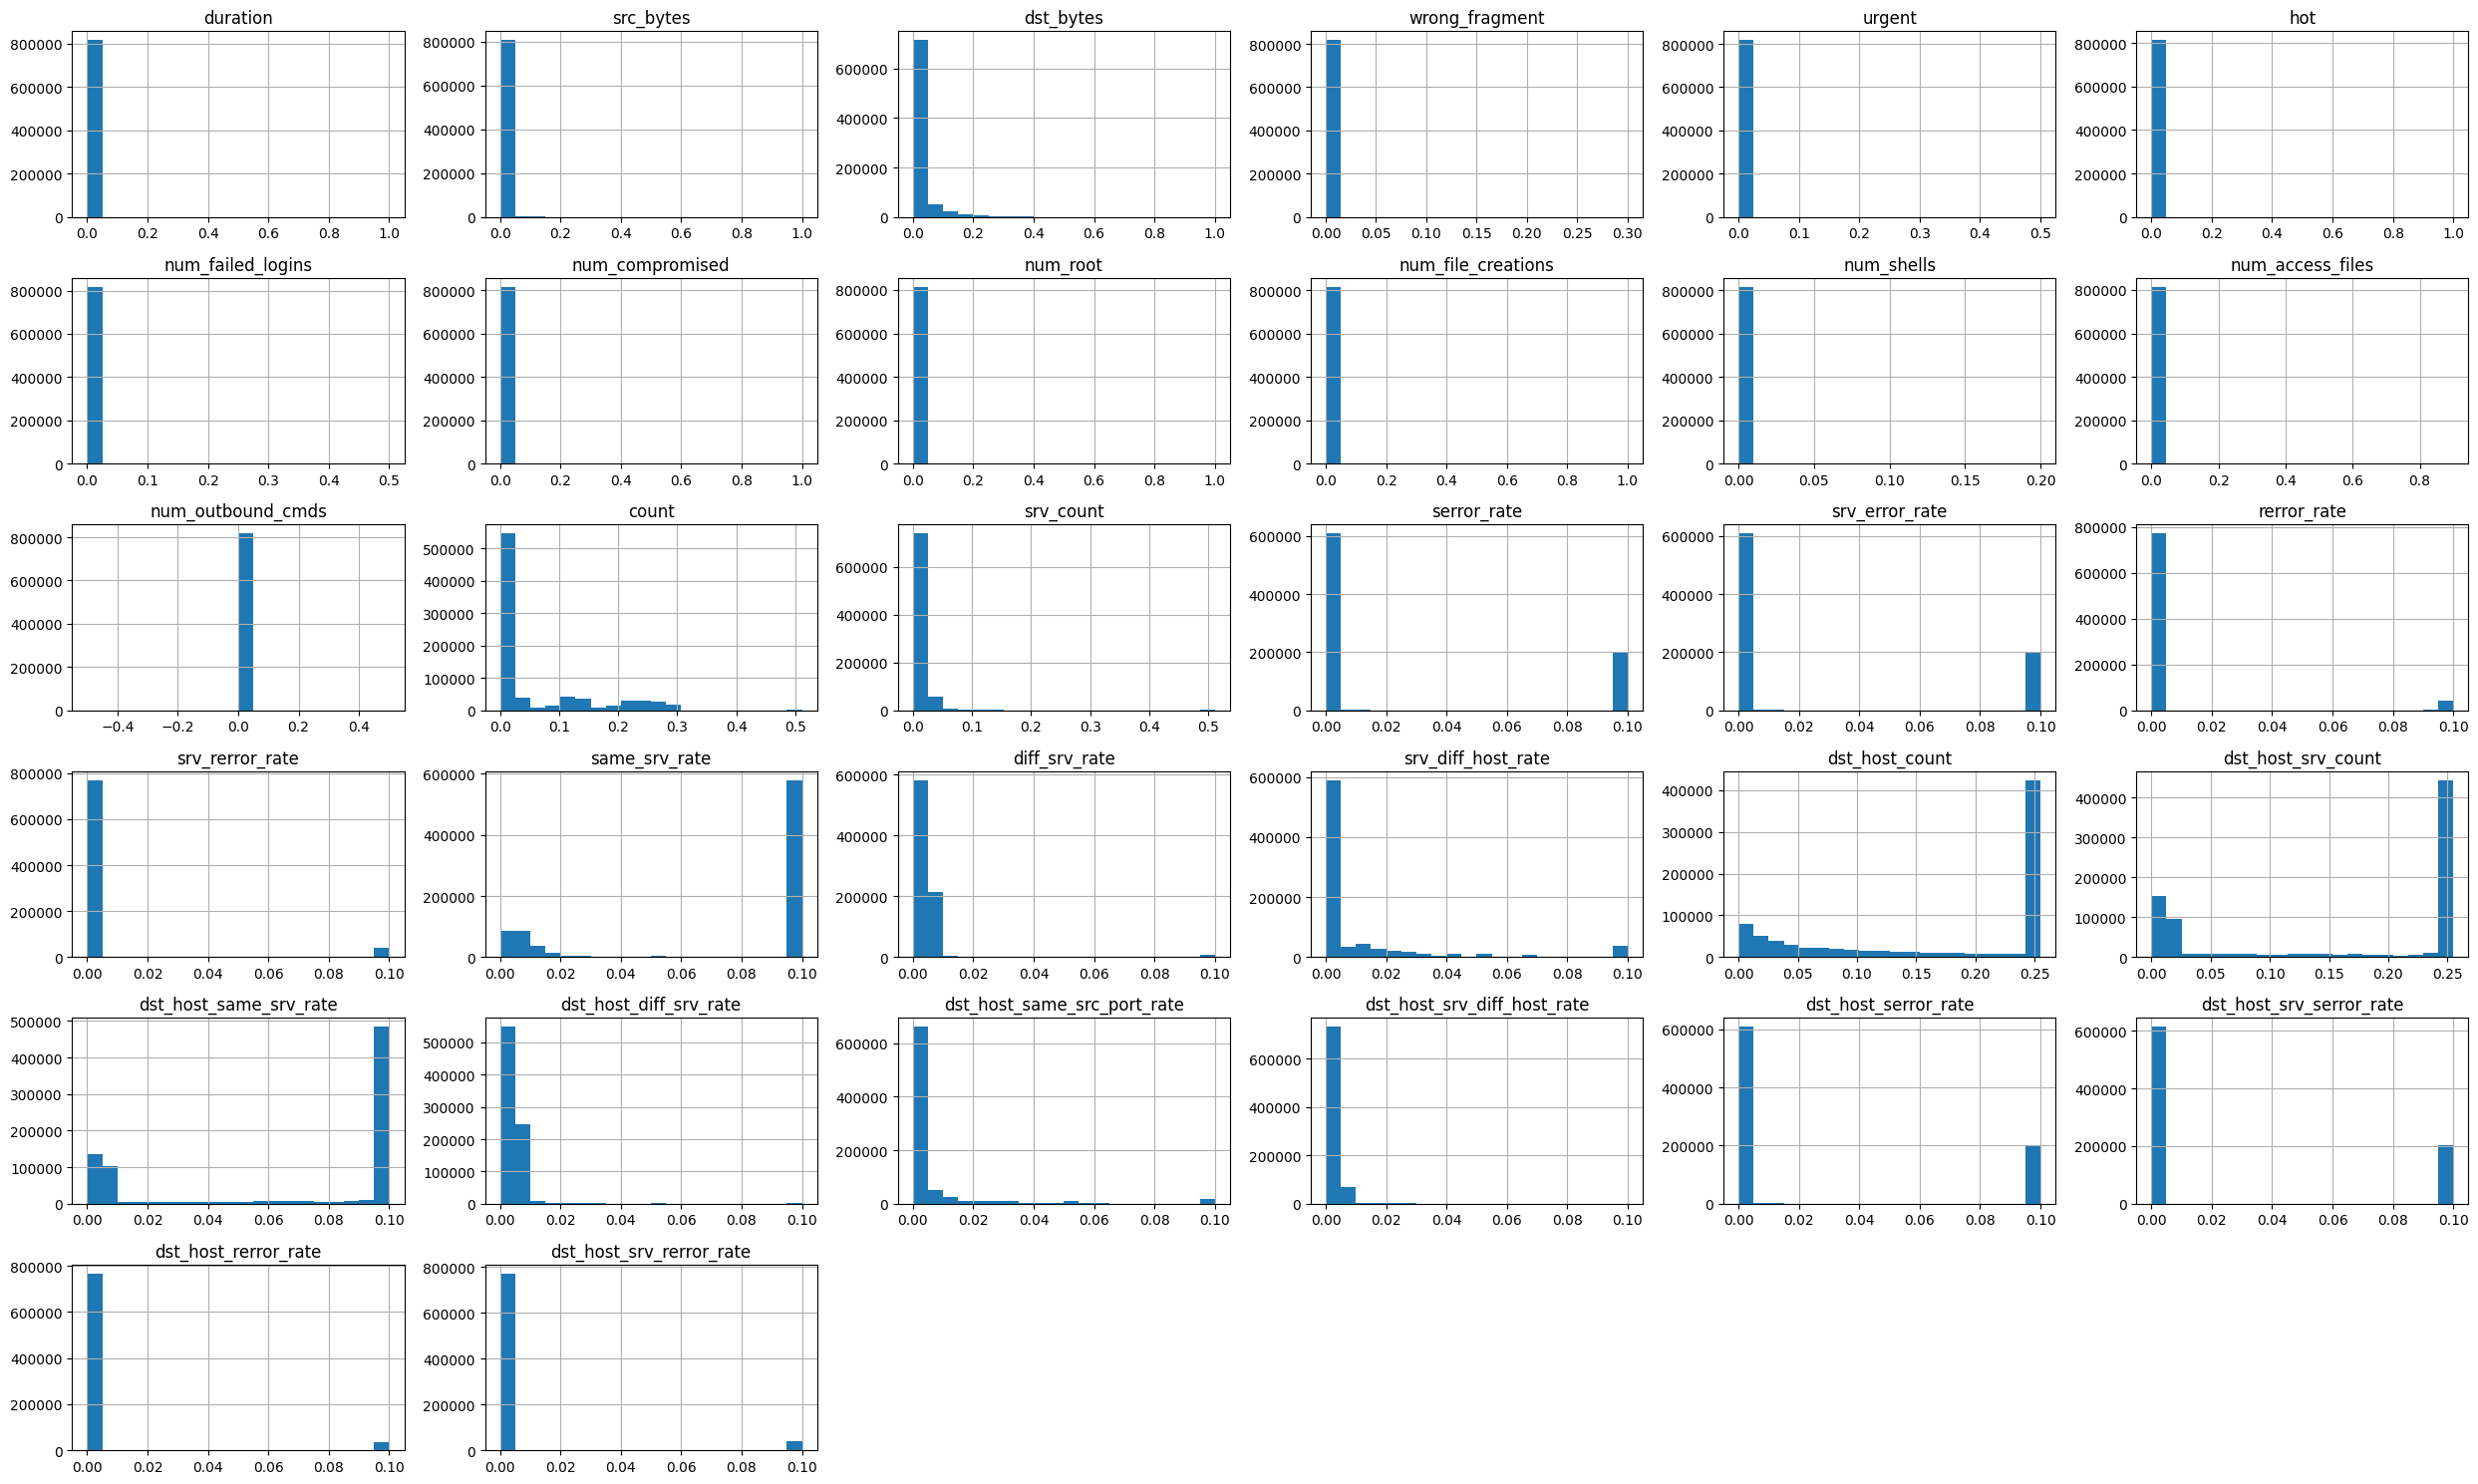

In [200]:
df[num_cols].hist(figsize = (25, 15), bins = 20)
plt.tight_layout()
plt.show()

In [201]:
# check the skewness

In [202]:
df[num_cols].skew().sort_values()

,0
same_srv_rate,-0.964930
dst_host_same_srv_rate,-0.657298
dst_host_count,-0.493123
dst_host_srv_count,-0.487615
num_outbound_cmds,0.000000
srv_error_rate,1.162258
dst_host_srv_serror_rate,1.166369
serror_rate,1.167887
dst_host_serror_rate,1.168300
count,1.704558


In [203]:
# < 0 --> left skew
# > 0 --> right skew
# 0 --> normal

In [204]:
# Since the algorithm chosen is XGBoost the skewness will be handled

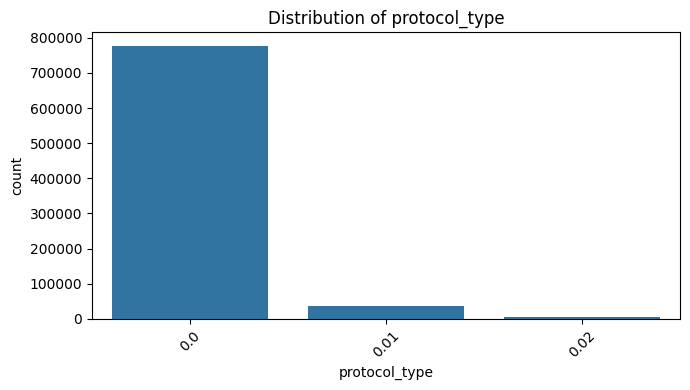

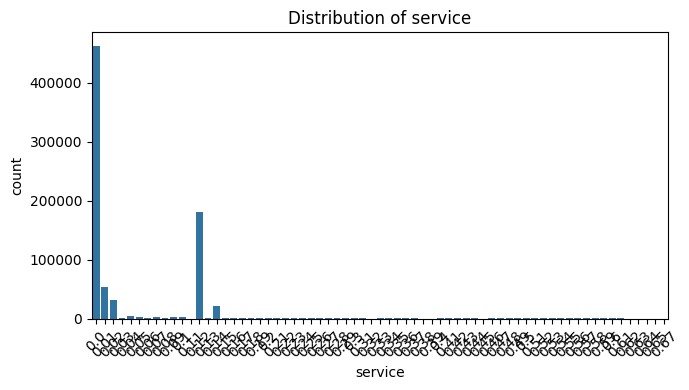

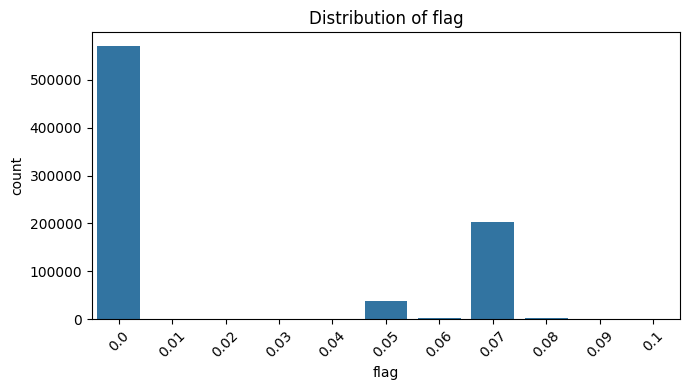

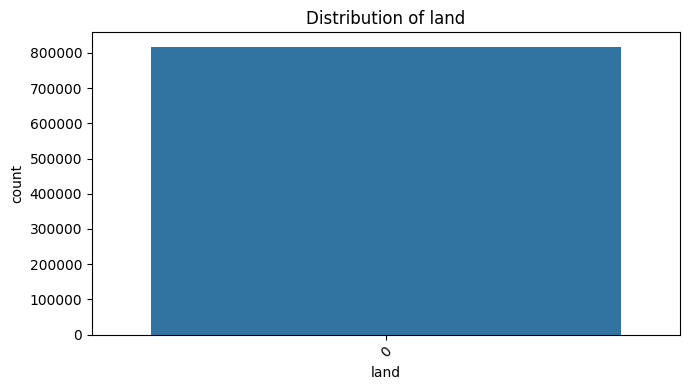

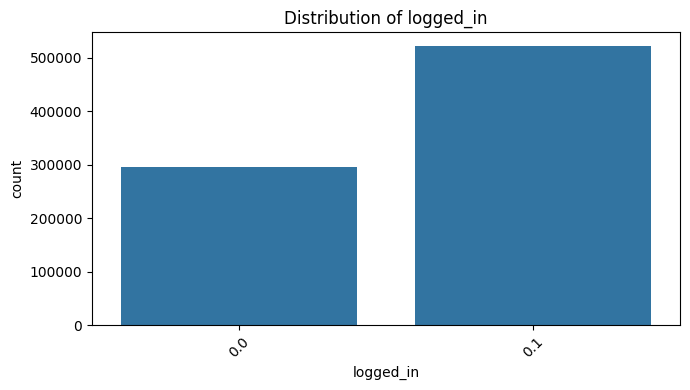

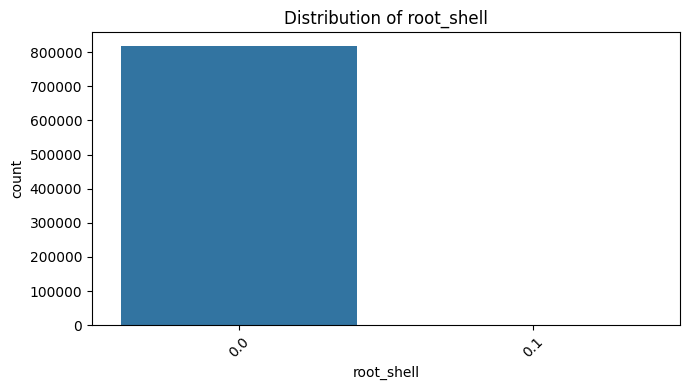

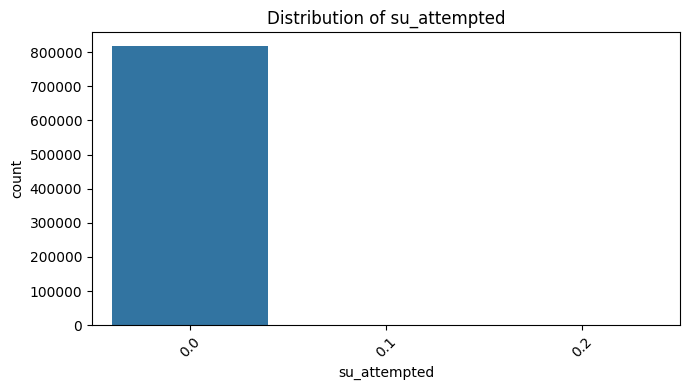

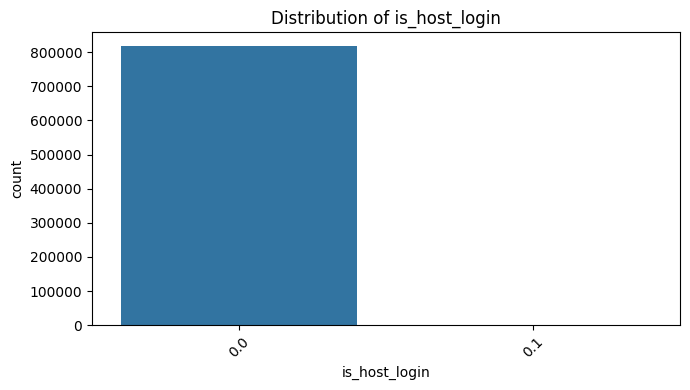

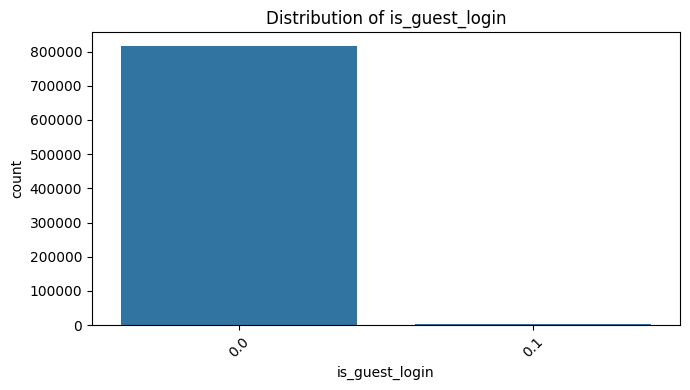

In [205]:
for col in df[cat_cols]:
  plt.figure(figsize = (7,4))
  sns.countplot(data = df, x = col)
  plt.xticks(rotation = 45)
  plt.title(f'Distribution of {col}')
  plt.tight_layout()
  plt.show()

In [206]:
# bivariate analysis --> between num_cols vs attack
                  #  --> between cat_cols vs attack

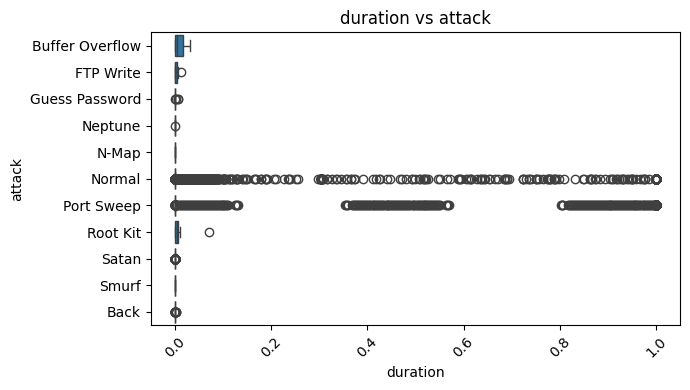

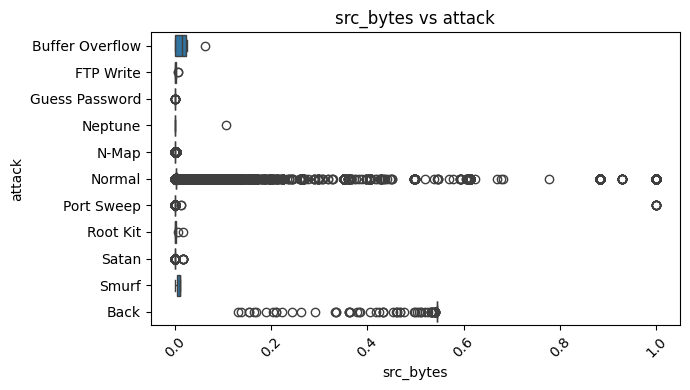

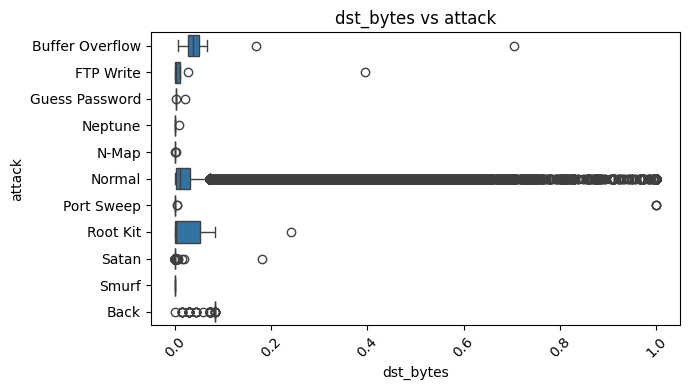

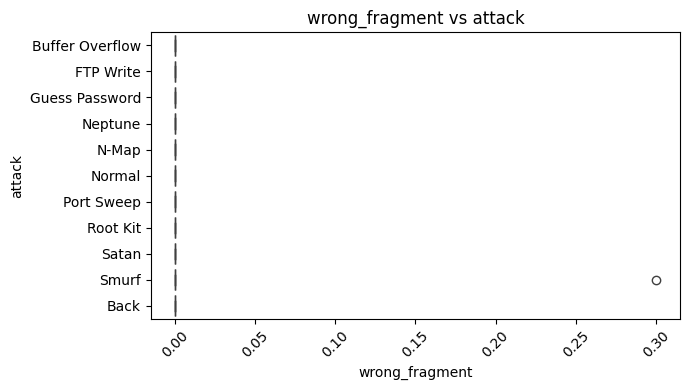

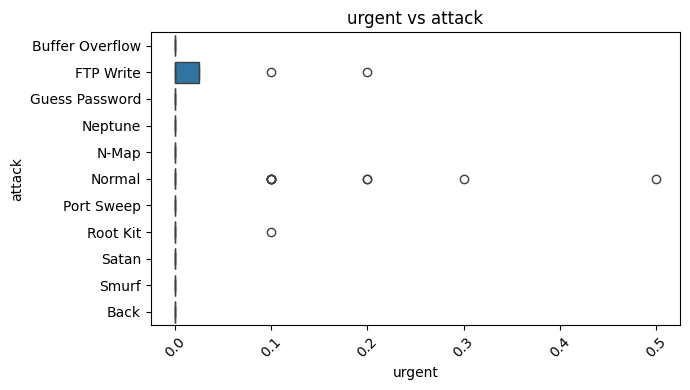

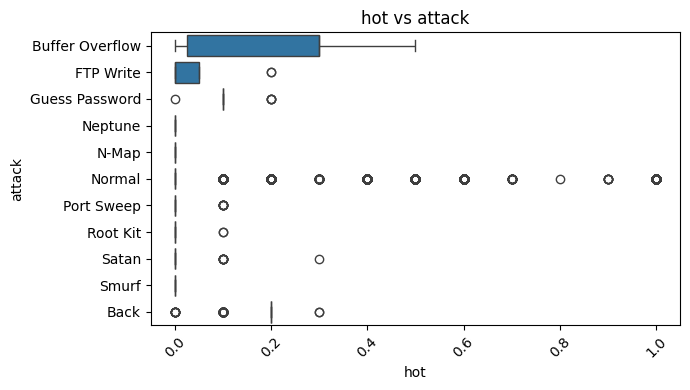

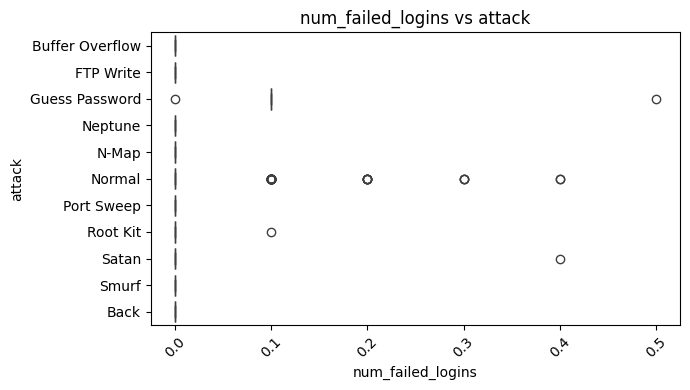

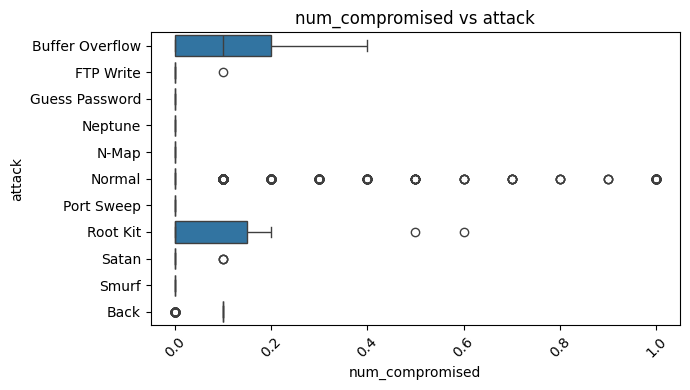

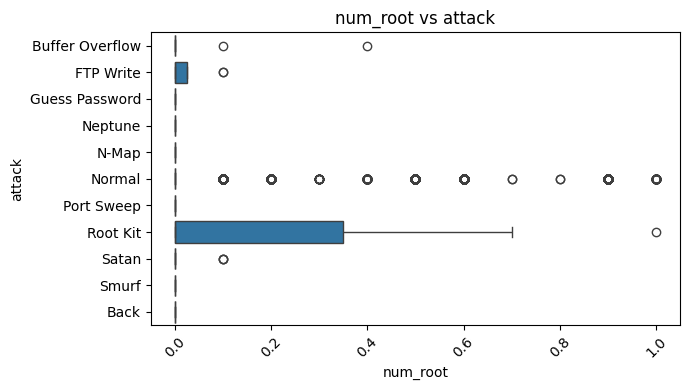

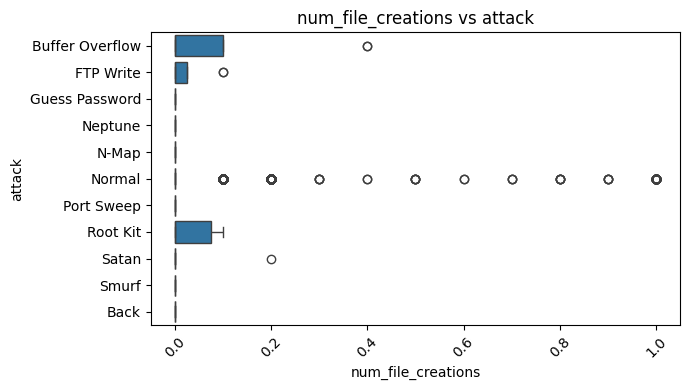

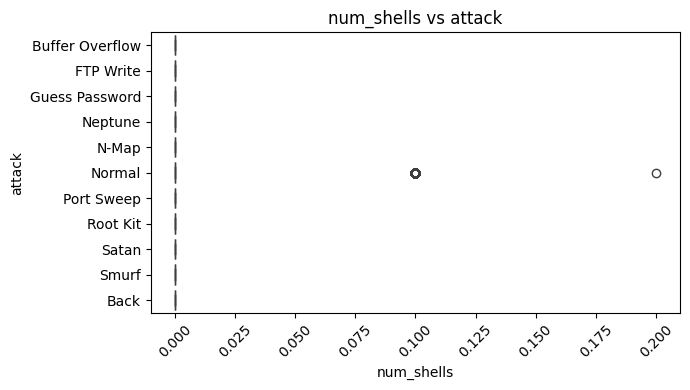

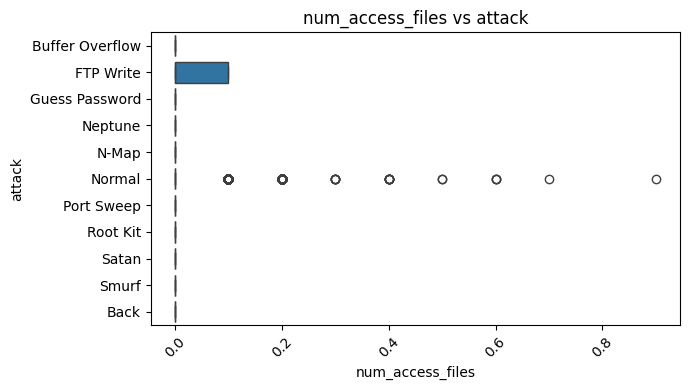

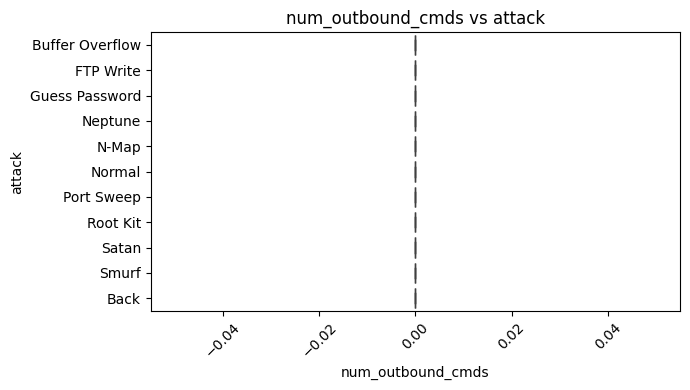

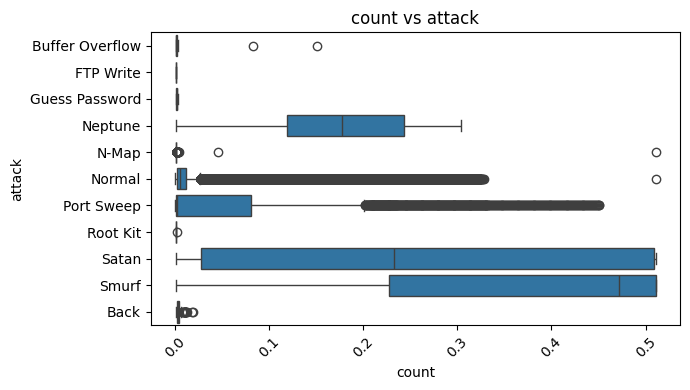

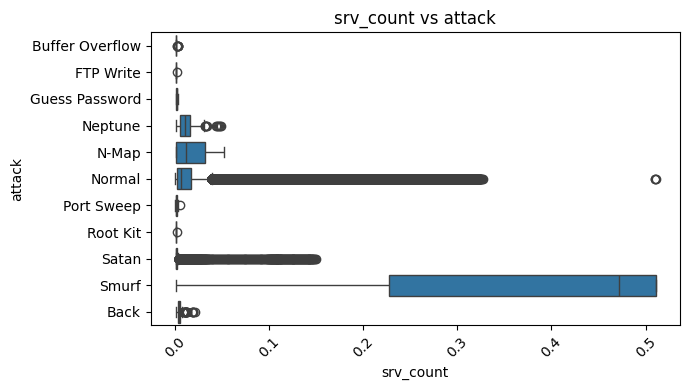

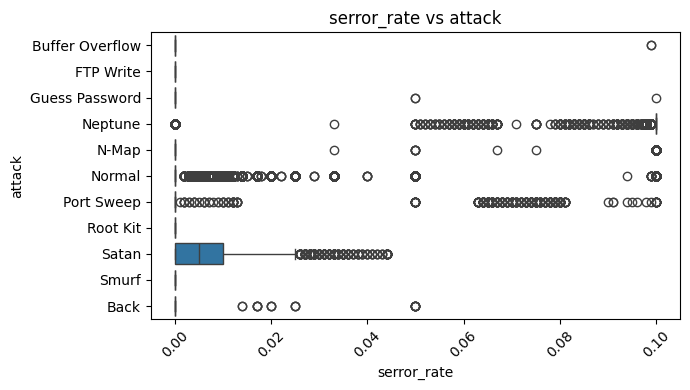

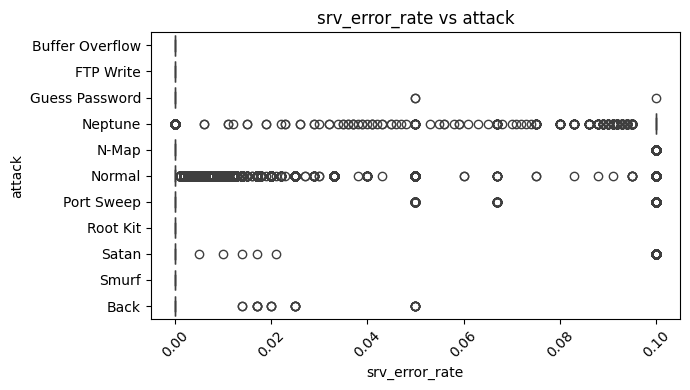

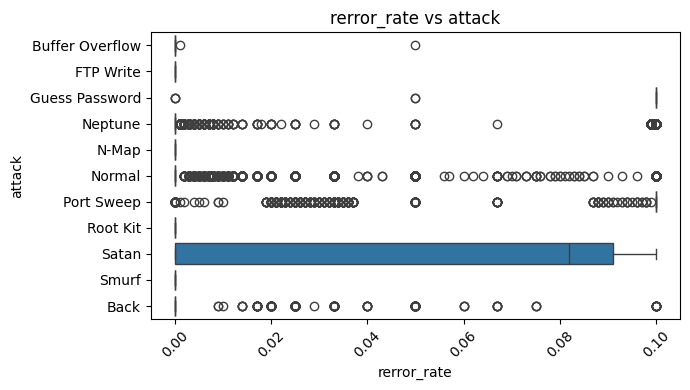

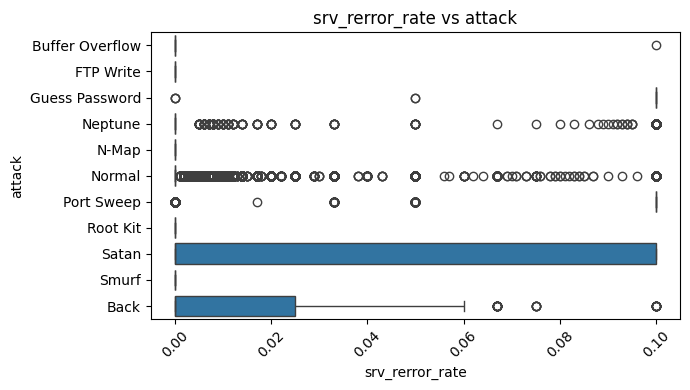

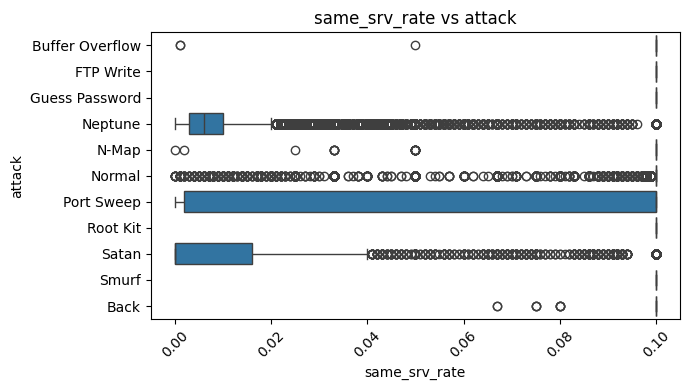

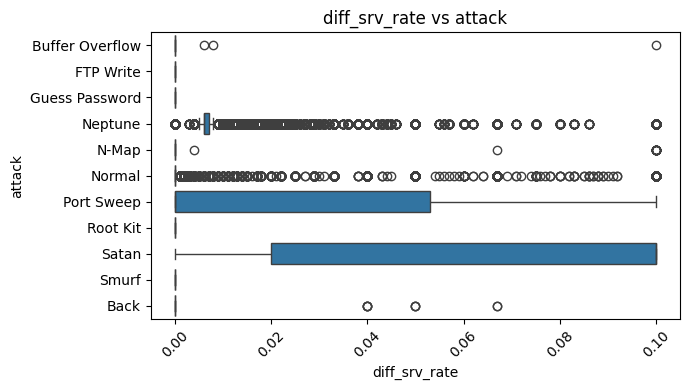

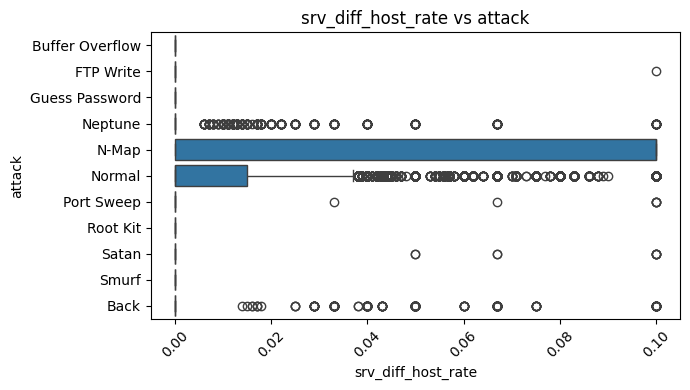

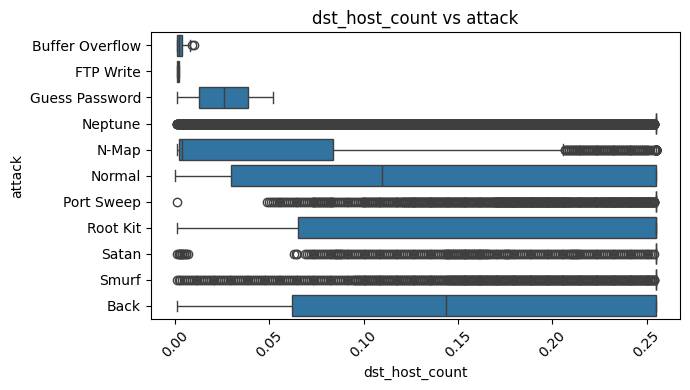

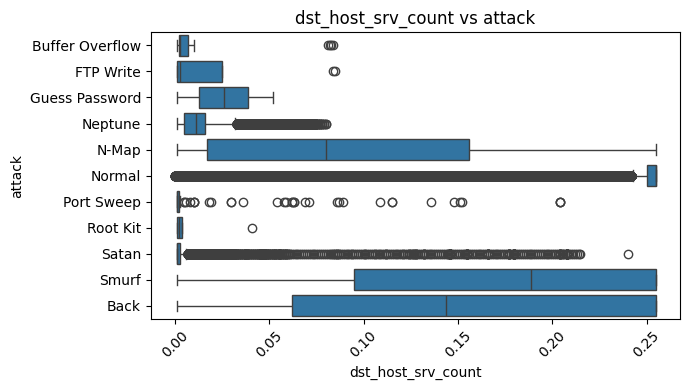

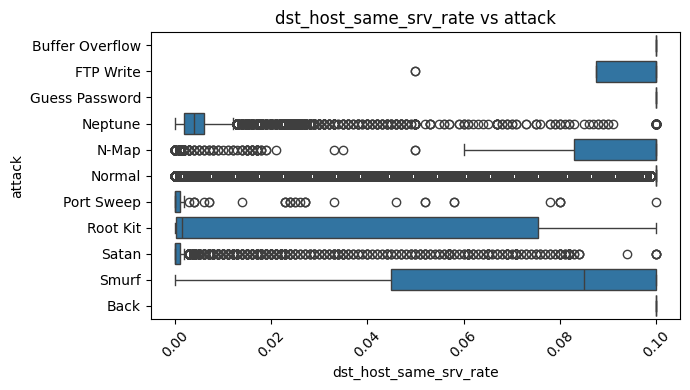

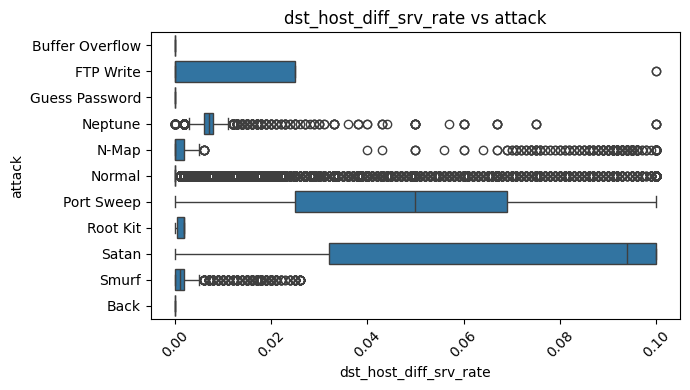

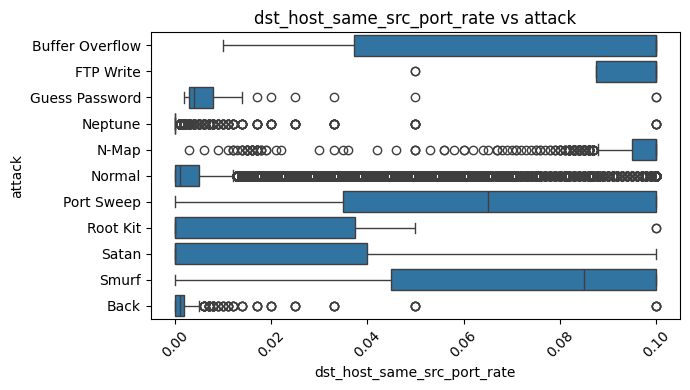

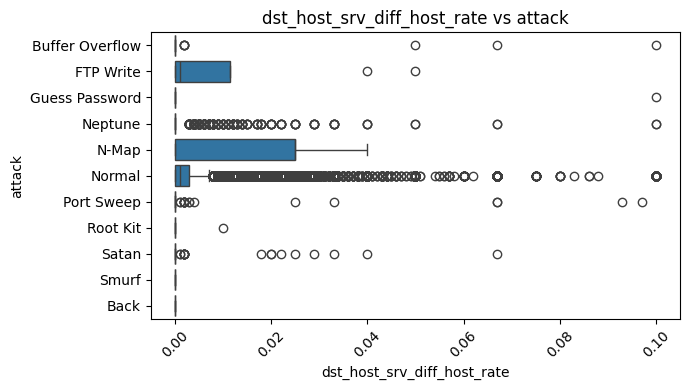

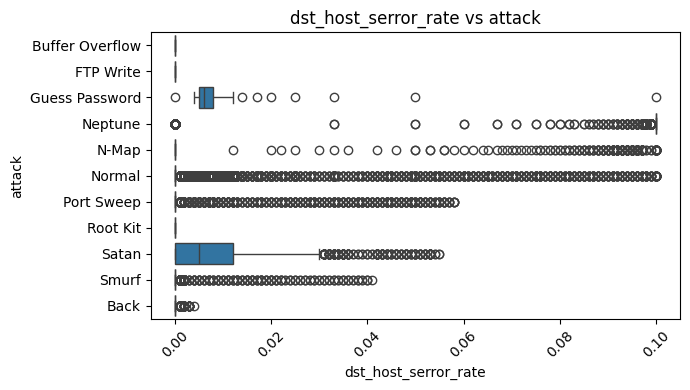

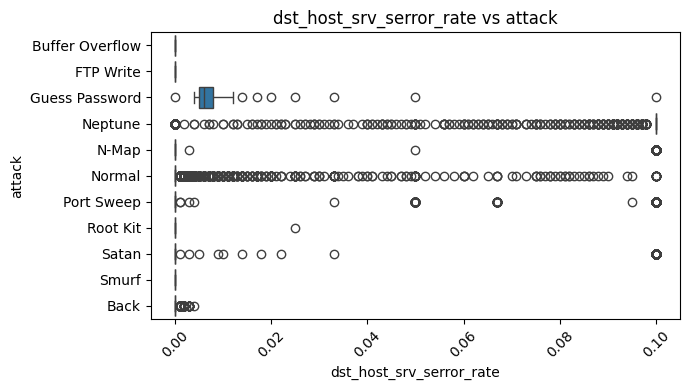

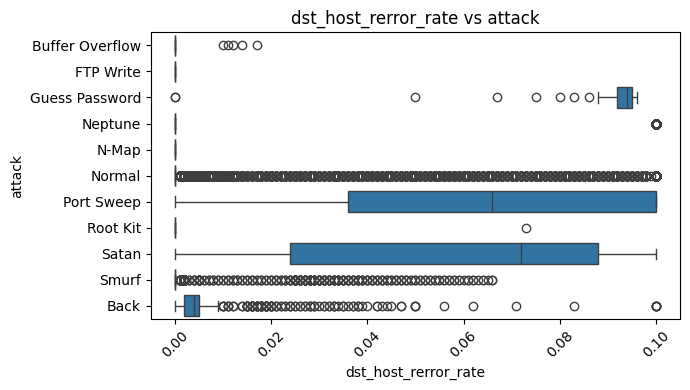

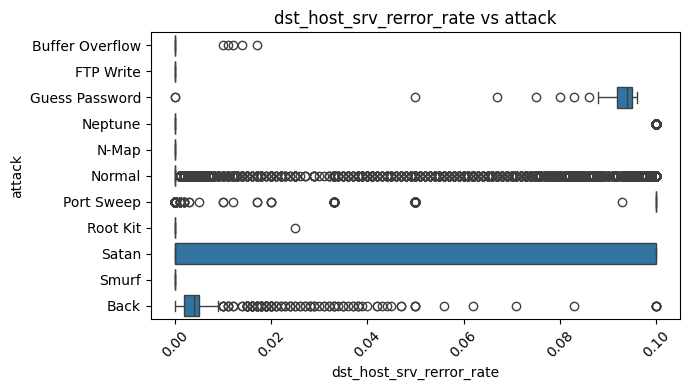

In [207]:
for col in df[num_cols]:
  plt.figure(figsize = (7,4))
  sns.boxplot(data = df, y = 'attack', x = col)
  plt.xticks(rotation = 45)
  plt.title(f'{col} vs attack')
  plt.tight_layout()
  plt.show()

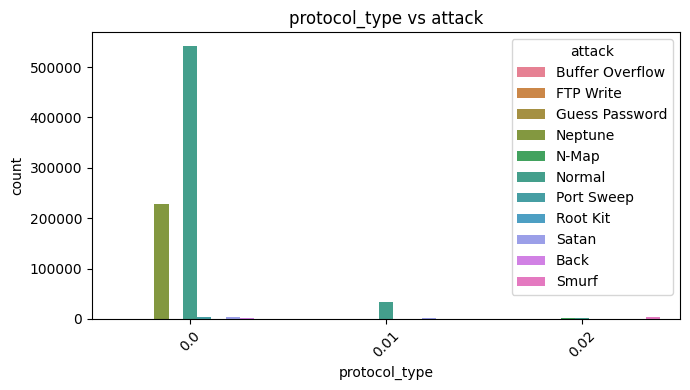

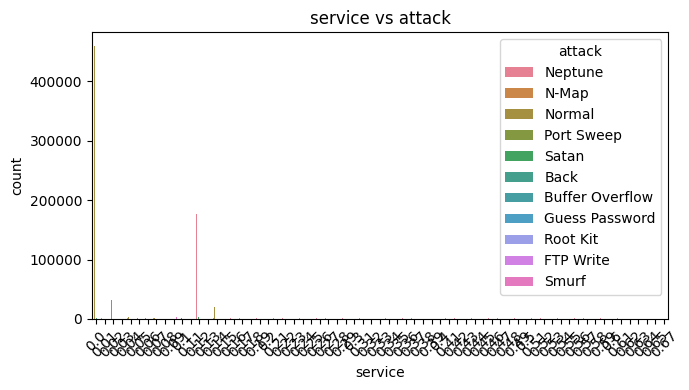

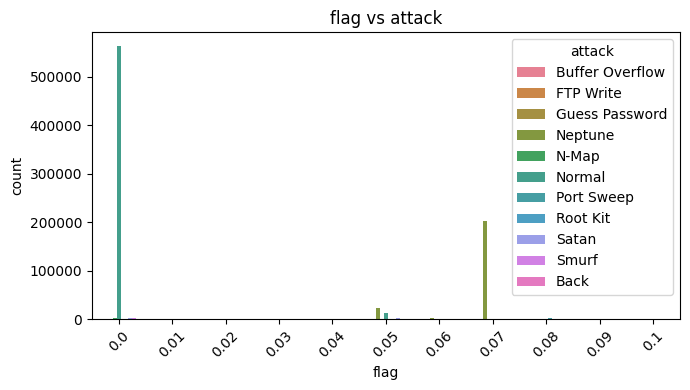

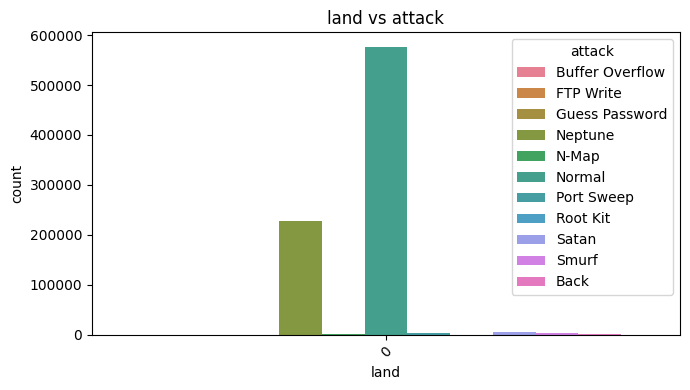

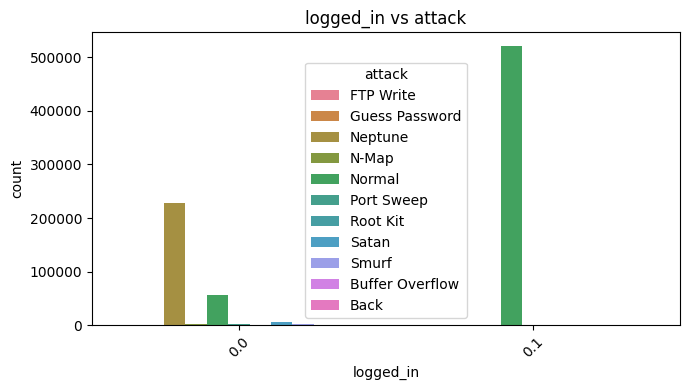

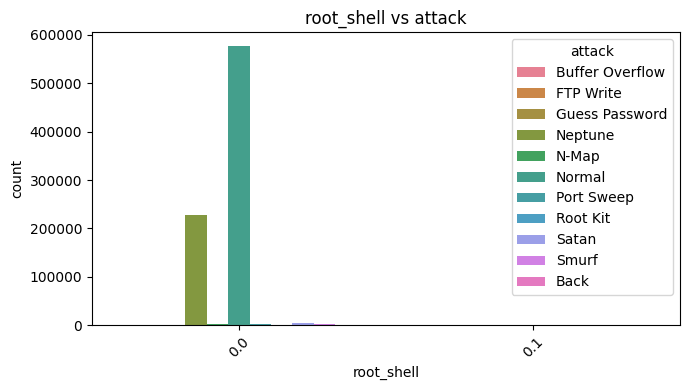

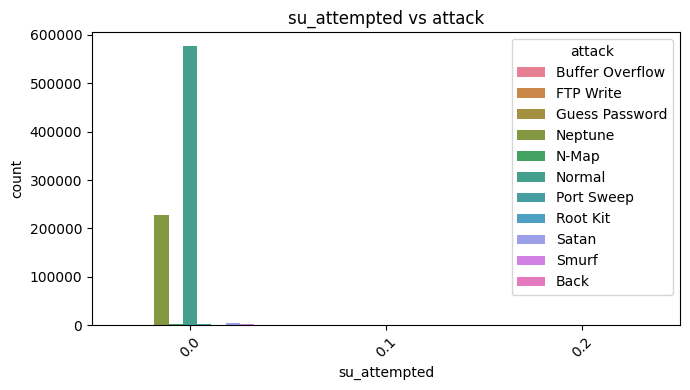

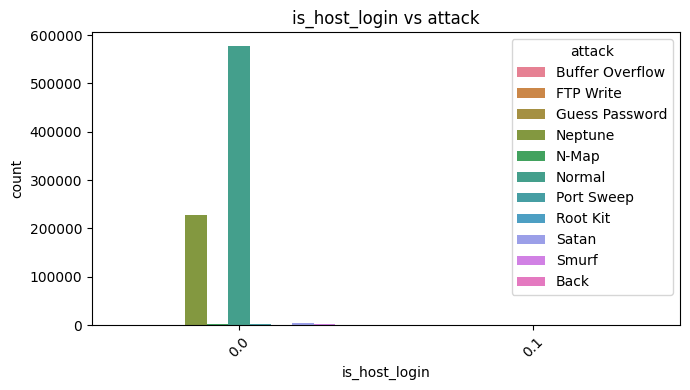

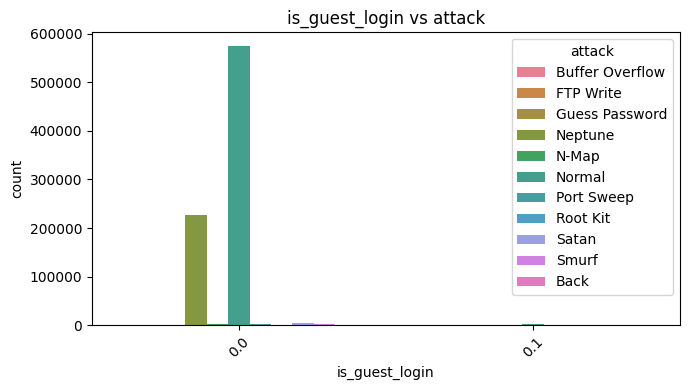

In [208]:
for col in df[cat_cols]:
  plt.figure(figsize = (7,4))
  sns.countplot(data = df, x = col, hue = 'attack')
  plt.xticks(rotation = 45)
  plt.title(f'{col} vs attack')
  plt.tight_layout()
  plt.show()

In [209]:
# separate the target and predictors

In [210]:
X = df.drop(columns = ['attack']).copy()
y = df['attack'].copy()

In [211]:
X.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0.0184,0.0,0.05,0.0,0.01511,0.02957,0,0.0,0.0,0.3,...,0.001,0.003,0.1,0.0,0.10,0.067,0.0,0.0,0.0,0.0
1,0.0305,0.0,0.05,0.0,0.01735,0.02766,0,0.0,0.0,0.3,...,0.002,0.004,0.1,0.0,0.05,0.050,0.0,0.0,0.0,0.0
2,0.0150,0.0,0.05,0.0,0.01587,0.06707,0,0.0,0.0,0.1,...,0.001,0.001,0.1,0.0,0.10,0.000,0.0,0.0,0.0,0.0
3,0.0060,0.0,0.05,0.0,0.02328,0.04551,0,0.0,0.0,0.3,...,0.001,0.001,0.1,0.0,0.10,0.000,0.0,0.0,0.0,0.0
4,0.0158,0.0,0.05,0.0,0.01567,0.03095,0,0.0,0.0,0.3,...,0.002,0.002,0.1,0.0,0.05,0.000,0.0,0.0,0.0,0.0


In [212]:
y.head()

,attack
0,Buffer Overflow
1,Buffer Overflow
2,Buffer Overflow
3,Buffer Overflow
4,Buffer Overflow


In [213]:
# split into train and test sets

In [214]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 123)

In [215]:
X_train.shape

(654040, 41)

In [216]:
X_test.shape

(163511, 41)

In [217]:
y_train.shape

(654040,)

In [218]:
y_test.shape

(163511,)

In [219]:
# separate num and cat features

In [220]:
X_train_num = X_train[num_cols]
X_test_num = X_test[num_cols]

X_train_cat = X_train[cat_cols]
X_test_cat = X_test[cat_cols]

In [221]:
# outliers treatment on num cols

In [222]:
def outliers_cap(train, test):
  lower = train.quantile(0.01)
  upper = train.quantile(0.99)

  train = train.clip(lower = lower, upper = upper, axis = 1)
  test = test.clip(lower = lower, upper = upper, axis = 1)

  return train, test

In [223]:
X_train_num, X_test_num = outliers_cap(X_train_num, X_test_num)

In [224]:
X_train_cat.head()

,protocol_type,service,flag,land,logged_in,root_shell,su_attempted,is_host_login,is_guest_login
330595,0.0,0.00,0.00,0,0.1,0.0,0.0,0.0,0.0
66227,0.0,0.12,0.07,0,0.0,0.0,0.0,0.0,0.0
123420,0.0,0.12,0.07,0,0.0,0.0,0.0,0.0,0.0
28526,0.0,0.12,0.07,0,0.0,0.0,0.0,0.0,0.0
71010,0.0,0.12,0.07,0,0.0,0.0,0.0,0.0,0.0


In [225]:
# since the binary features are already in form of 0s and 1s, only the nominal features need to be encoded

In [226]:
nominal_cols = ['protocol_type', 'service', 'flag']
binary_cols = [
    'land', 'logged_in', 'root_shell',
    'su_attempted', 'is_host_login', 'is_guest_login'
]

In [227]:
# ohe

In [228]:
ohe = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)
# handle_unknown --> handles categories that are present in the test data but not in train data
# sparse_output --> dense Numpy array

In [229]:
X_train_nom = pd.DataFrame(ohe.fit_transform(X_train_cat[nominal_cols]), columns = ohe.get_feature_names_out(nominal_cols), index = X_train_cat.index)
X_test_nom = pd.DataFrame(ohe.transform(X_test_cat[nominal_cols]), columns = ohe.get_feature_names_out(nominal_cols), index = X_test_cat.index)

In [230]:
# now combine the X_train and X_test

In [231]:
X_train = pd.concat([X_train_num, X_train_cat[binary_cols], X_train_nom], axis = 1)
X_test = pd.concat([X_test_num, X_test_cat[binary_cols], X_test_nom], axis = 1)

In [232]:
X_train.shape

(654040, 118)

In [233]:
X_test.shape

(163511, 118)

In [234]:
# for the first solution, we will have to ransform y into 0 and 1 values: 0: Normal, 1: Attack

In [235]:
y_train_binary = y_train.apply(lambda x: 0 if x == 'Normal' else 1)
y_test_binary = y_test.apply(lambda x: 0 if x == 'Normal' else 1)

In [236]:
y_train_binary.value_counts()

,count
attack,
0,461249
1,192791


In [237]:
# since there are 118 features, let's do RFE

In [238]:
xgb = XGBClassifier(n_estimators = 100, max_depth = 6, random_state = 123)

In [239]:
rfe = RFE(estimator = xgb, n_features_to_select = 10, step = 10)

In [240]:
rfe.fit_transform(X_train, y_train_binary)

array([[0.00276, 0.003  , 0.1    , ..., 0.     , 0.     , 0.     ],
       [0.     , 0.019  , 0.018  , ..., 1.     , 0.     , 0.     ],
       [0.     , 0.009  , 0.006  , ..., 1.     , 0.     , 0.     ],
       ...,
       [0.     , 0.02   , 0.014  , ..., 1.     , 0.     , 0.     ],
       [0.00279, 0.026  , 0.1    , ..., 0.     , 0.     , 0.     ],
       [0.00228, 0.014  , 0.1    , ..., 0.     , 0.     , 0.     ]])

In [241]:
sel_cols = X_train.columns[rfe.support_]

In [242]:
sel_cols

Index(['src_bytes', 'srv_count', 'same_srv_rate', 'dst_host_srv_serror_rate',
       'protocol_type_0.02', 'service_0.0', 'service_0.09', 'service_0.12',
       'service_0.39', 'flag_0.08'],
      dtype='object')

In [243]:
rfe.ranking_

array([ 4,  1,  3, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12,  2,  1,  5,  6,
        3,  4,  1,  5,  5,  3,  2,  2,  4,  3,  2,  3,  1,  3,  4, 11,  3,
        2, 11, 11, 11,  3,  5,  1,  1,  5,  5,  5,  4,  4,  4,  5,  6,  1,
        3,  2,  1, 10,  3, 10,  6,  9,  6,  6,  6, 11, 11, 11, 11, 11, 11,
       10, 10, 10, 10, 10,  4, 10, 10, 10,  6,  9,  9,  1,  9,  9,  9,  9,
        9,  9,  8,  8,  8,  9,  8,  8,  8,  8,  8,  8,  8,  7,  7,  7,  7,
        7,  7,  7,  7,  7,  4,  7,  6,  6,  4,  2,  2,  5,  1,  5,  6])

In [244]:
X_train_sel = X_train[sel_cols]
X_test_sel = X_test[sel_cols]

In [245]:
# now we use SMOTE for handling the class imbalance problem

In [246]:
smote = SMOTE(random_state =123)

In [247]:
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train_binary)

In [248]:
# now let's use gcv to tune the hyper parameters

In [249]:
param_grid = {'n_estimators':[100], 'max_depth':[3,5], 'subsample':[0.8], 'colsample_bytree':[0.8], 'learning_rate':[0.5, 0.1]}
# subsample --> each tree uses randomly 80% of observations
# colsample_bytree --> proportion of columns selected when building the tree

In [250]:
gcv = GridSearchCV(estimator = xgb, param_grid = param_grid, n_jobs = -1, verbose = True)

In [251]:
gcv.fit(X_train_smote, y_train_smote)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


GridSearchCV(estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     lear...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=6,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=100,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8], 'learning_rate': [0.5, 0.1],
                         'max_depth': [3, 5], 'n_estimators': [100],
                         'subsample': [0.8]},
             verbose=True)

In [252]:
gcv.best_score_

np.float64(0.9997127364634476)

In [253]:
gcv.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.5,
 'max_depth': 5,
 'n_estimators': 100,
 'subsample': 0.8}

In [254]:
gcv.cv_results_

{'mean_fit_time': array([3.74843888, 4.50056624, 3.59363313, 4.13663507]),
 'std_fit_time': array([0.10629426, 0.2196707 , 0.08387688, 0.12691794]),
 'mean_score_time': array([0.13048782, 0.18770108, 0.12812271, 0.19061298]),
 'std_score_time': array([0.00159666, 0.00097641, 0.00097516, 0.00179798]),
 'param_colsample_bytree': masked_array(data=[0.8, 0.8, 0.8, 0.8],
              mask=[False, False, False, False],
        fill_value=1e+20),
 'param_learning_rate': masked_array(data=[0.5, 0.5, 0.1, 0.1],
              mask=[False, False, False, False],
        fill_value=1e+20),
 'param_max_depth': masked_array(data=[3, 5, 3, 5],
              mask=[False, False, False, False],
        fill_value=999999),
 'param_n_estimators': masked_array(data=[100, 100, 100, 100],
              mask=[False, False, False, False],
        fill_value=999999),
 'param_subsample': masked_array(data=[0.8, 0.8, 0.8, 0.8],
              mask=[False, False, False, False],
        fill_value=1e+20),
 'params':

In [255]:
xgb = gcv.best_estimator_

In [256]:
xgb.fit(X_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.5, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [257]:
y_pred = xgb.predict(X_test_sel)

In [258]:
y_pred

array([1, 1, 0, ..., 0, 0, 0])

In [259]:
print(classification_report(y_test_binary, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    115461
           1       1.00      1.00      1.00     48050

    accuracy                           1.00    163511
   macro avg       1.00      1.00      1.00    163511
weighted avg       1.00      1.00      1.00    163511



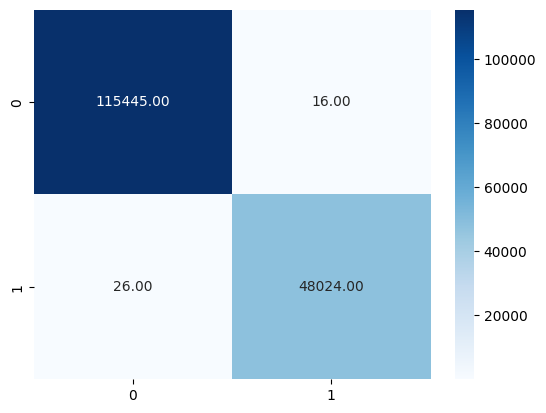

In [260]:
sns.heatmap(confusion_matrix(y_test_binary, y_pred), annot = True, cmap = 'Blues', fmt = '.2f')
plt.show()

In [261]:
# now let's do the mult class classification

In [262]:
le = LabelEncoder()

In [263]:
y_train_multi = le.fit_transform(y_train)
y_test_multi = le.transform(y_test)

In [266]:
rfe = RFE(estimator = xgb, n_features_to_select = 5, step = 10)

In [267]:
rfe.fit_transform(X_train, y_train_multi)

array([[0.   , 0.   , 1.   , 1.   , 0.   ],
       [0.007, 0.007, 0.   , 0.   , 0.   ],
       [0.006, 0.008, 0.   , 0.   , 0.   ],
       ...,
       [0.006, 0.007, 0.   , 0.   , 0.   ],
       [0.   , 0.   , 1.   , 1.   , 0.   ],
       [0.   , 0.   , 1.   , 1.   , 0.   ]])

In [ ]:
sel_cols = X_train.columns[rfe.support_]

In [268]:
X_train_sel = X_train[sel_cols]
X_test_sel = X_test[sel_cols]

In [269]:
X_train_mul_smote, y_train_mul_smote = smote.fit_resample(X_train_sel, y_train_multi)

In [270]:
gcv.fit(X_train_mul_smote, y_train_mul_smote)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


GridSearchCV(estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     lear...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=6,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=100,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8], 'learning_rate': [0.5, 0.1],
                         'max_depth': [3, 5], 'n_estimators': [100],
                         'subsample': [0.8]},
             verbose=True)

In [271]:
gcv.best_score_

np.float64(0.9281709208917575)

In [272]:
gcv.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.5,
 'max_depth': 5,
 'n_estimators': 100,
 'subsample': 0.8}

In [273]:
gcv.cv_results_

{'mean_fit_time': array([226.7061337 , 257.96029491, 225.3543921 , 247.19575958]),
 'std_fit_time': array([3.53785893, 8.54642037, 2.55275288, 3.14747005]),
 'mean_score_time': array([ 5.9854362 , 10.33467121,  7.52585902, 10.87486072]),
 'std_score_time': array([1.13215414, 0.09507777, 0.03254844, 0.21167527]),
 'param_colsample_bytree': masked_array(data=[0.8, 0.8, 0.8, 0.8],
              mask=[False, False, False, False],
        fill_value=1e+20),
 'param_learning_rate': masked_array(data=[0.5, 0.5, 0.1, 0.1],
              mask=[False, False, False, False],
        fill_value=1e+20),
 'param_max_depth': masked_array(data=[3, 5, 3, 5],
              mask=[False, False, False, False],
        fill_value=999999),
 'param_n_estimators': masked_array(data=[100, 100, 100, 100],
              mask=[False, False, False, False],
        fill_value=999999),
 'param_subsample': masked_array(data=[0.8, 0.8, 0.8, 0.8],
              mask=[False, False, False, False],
        fill_value=1e+20)

In [274]:
xgb = gcv.best_estimator_

In [301]:
y_pred_mul = xgb.predict(X_train_mul_smote)

In [302]:
y_pred_mul

array([ 6,  5,  5, ..., 10, 10, 10])

In [277]:
# save the results

In [278]:
# save the binary classification results

In [280]:
y_pred = pd.Series(y_pred)

In [281]:
y_pred = y_pred.map({0:'Normal', 1:'Attack'})

In [282]:
binary_results = pd.DataFrame({'predictions':y_pred})

In [312]:
binary_results.to_csv(filepath + 'binary_results.csv', index = False)

In [313]:
binary_results.head()

,predictions
0,Attack
1,Attack
2,Normal
3,Normal
4,Normal


In [285]:
# save the multi class predictions

In [286]:
y_pred_mul

array([ 6,  5,  5, ..., 10, 10, 10])

In [303]:
y_pred_mul2  = pd.Series(y_pred_mul)

In [305]:
y_pred_mul2 = y_pred_mul2.map({0:'Back', 1:'Buffer Overflow', 2:'FTP Write', 3:'Guess Password', 4:'N-Map',
       5:'Neptune', 6:'Normal', 7:'Port Sweep', 8:'Root Kit', 9:'Satan', 10:'Smurf'})

In [306]:
multiclass_results = pd.DataFrame({'predictions':y_pred_mul2})

In [314]:
multiclass_results.to_csv(filepath + 'multiclass_results.csv', index = False)

In [308]:
multiclass_results.head()

,predictions
0,Normal
1,Neptune
2,Neptune
3,Neptune
4,Neptune
